In [2]:
# Стандартный импорт
import pandas as pd
import numpy as np

# Импорт конкретных функций или классов
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Импорт с псевдонимом (удобно для длинных названий)
import matplotlib.pyplot as plt
import shap

In [3]:
data = pd.read_csv("Customer_Churn.csv")

In [4]:
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [5]:
# Размер таблицы: (число строк, число столбцов)
print(data.shape)

# Первые 5 строк — глазами проверяем, что колонки на месте
data.head()

# Типы данных и наличие пропусков
data.info()

# Базовая статистика по числовым признакам
data.describe()

# Проверка пропусков по колонкам (в этом датасете есть "дыра" в TotalCharges)
data.isna().sum()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

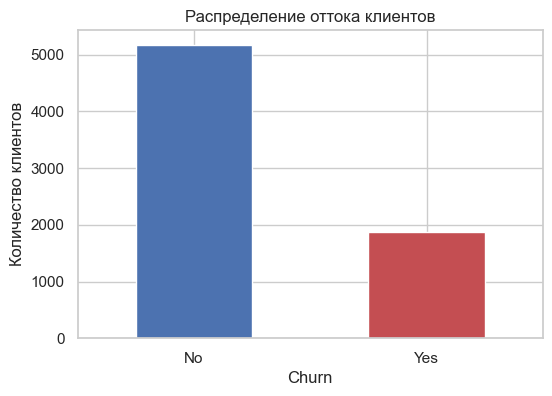

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(6, 4))
data["Churn"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"])
plt.title("Распределение оттока клиентов")
plt.xlabel("Churn")
plt.ylabel("Количество клиентов")
plt.xticks(rotation=0)
plt.show()

# В процентах — чтобы сразу понять масштаб дисбаланса
print(data["Churn"].value_counts(normalize=True).round(3) * 100)

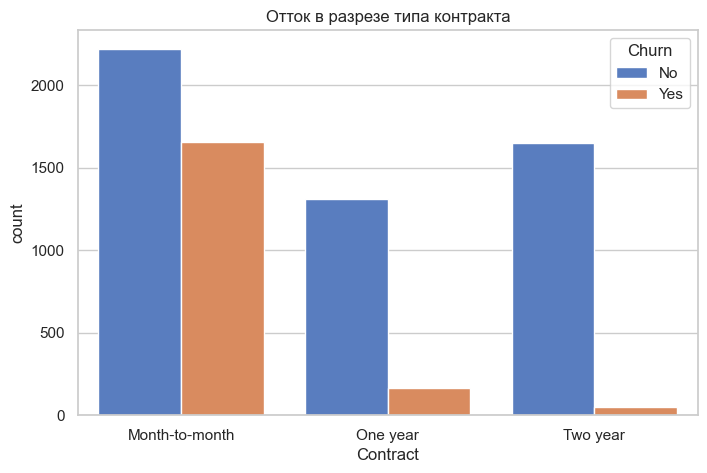

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Contract", hue="Churn")
plt.title("Отток в разрезе типа контракта")
plt.show()

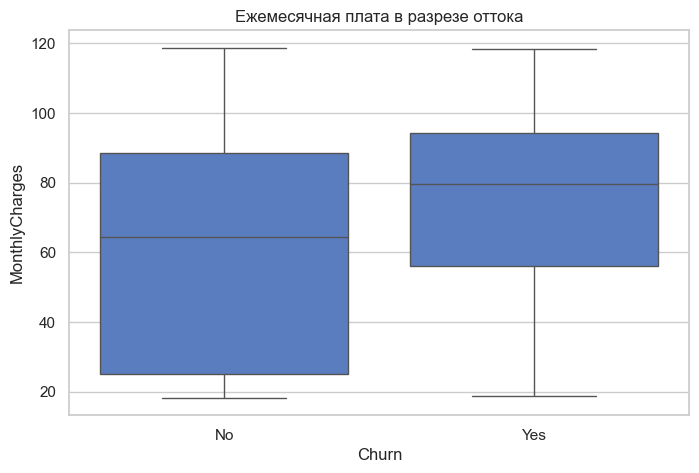

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Churn", y="MonthlyCharges")
plt.title("Ежемесячная плата в разрезе оттока")
plt.show()

In [10]:
# Заглянем, что там не так
data["TotalCharges"].head(10)

# Превращаем в число, пробелы станут NaN
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

# Сколько пропусков появилось
data["TotalCharges"].isna().sum()

11

In [11]:
for col in data.columns:
    print("=" * 60)
    print(f"Столбец: {col}")
    print(f"Уникальных значений: {data[col].nunique()}")
    print(f"Пропусков: {data[col].isna().sum()}")
    print("-" * 60)
    # Показываем значения и их частоты (топ-10, чтобы не заспамить вывод)
    print(data[col].value_counts(dropna=False).head(10))
    print()

Столбец: customerID
Уникальных значений: 7043
Пропусков: 0
------------------------------------------------------------
customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
5855-EIBDE    1
8166-ZZTFS    1
0129-KPTWJ    1
9128-CPXKI    1
9509-MPYOD    1
Name: count, dtype: int64

Столбец: gender
Уникальных значений: 2
Пропусков: 0
------------------------------------------------------------
gender
Male      3555
Female    3488
Name: count, dtype: int64

Столбец: SeniorCitizen
Уникальных значений: 2
Пропусков: 0
------------------------------------------------------------
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Столбец: Partner
Уникальных значений: 2
Пропусков: 0
------------------------------------------------------------
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Столбец: Dependents
Уникальных значений: 2
Пропусков: 0
------------------------------------------------------------
Dependents
No     4933
Yes    2110

In [12]:
import pandas as pd   # на случай, если ядро перезапускалось

# ── Шаг 0: объединяем "No X service" с "No" ──────────────────
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

for col in service_cols:
    data[col] = data[col].replace({"No internet service": "No",
                                   "No phone service": "No"})

# ── Шаг 1: словарь маппинга ──────────────────────────────────
binary_map = {
    "gender":           {"Female": 0, "Male": 1},
    "Partner":          {"No": 0, "Yes": 1},
    "Dependents":       {"No": 0, "Yes": 1},
    "PhoneService":     {"No": 0, "Yes": 1},
    "PaperlessBilling": {"No": 0, "Yes": 1},
    "Churn":            {"No": 0, "Yes": 1},   # целевая переменная
}

# Все "No X service" после Шага 0 тоже стали бинарными
for col in service_cols:
    binary_map[col] = {"No": 0, "Yes": 1}

# ── Шаг 2: применяем маппинг ─────────────────────────────────
for col, mapping in binary_map.items():
    data[col] = data[col].map(mapping)

# ── Шаг 3: порядковое кодирование Contract ───────────────────
data["Contract"] = data["Contract"].map({
    "Month-to-month": 0,
    "One year": 1,
    "Two year": 2,
})

print("Готово. Проверка:")
print(data[binary_map.keys()].dtypes.value_counts())

Готово. Проверка:
int64    13
Name: count, dtype: int64


In [13]:
ЭтАП 2

SyntaxError: invalid syntax (3693204046.py, line 1)

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, classification_report

data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data["TotalCharges"] = data["TotalCharges"].fillna(0)

# customerID — не признак, а идентификатор.
data = data.drop(columns=["customerID"])

X = data.drop(columns=["Churn"])
y = data["Churn"]

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = ["InternetService", "PaymentMethod"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,   # критично при дисбалансе: сохраняет долю классов
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля оттока в train: {y_train.mean():.3f}, в test: {y_test.mean():.3f}")

preprocessor = ColumnTransformer(
    transformers=[
        # Числа → StandardScaler (нужно для LogisticRegression)
        ("num", StandardScaler(), numeric_features),
        # Номинальные категории → One-Hot с drop="first"
        # sparse_output=False — чтобы получить плотную numpy-матрицу
        # (в sklearn < 1.2 параметр называется sparse)
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
         categorical_features),
    ],
    remainder="passthrough",  # уже закодированные бинарные/ordinal — пропускаем
)

Train: (5634, 19), Test: (1409, 19)
Доля оттока в train: 0.265, в test: 0.265


In [15]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",   # боремся с дисбалансом ~73/27
        random_state=42,
    )),
])

In [16]:
model.fit(X_train, y_train)

# Предсказания
y_pred_proba = model.predict_proba(X_test)[:, 1]   # вероятность класса "Churn=1"
y_pred = model.predict(X_test)                       # жёсткий порог 0.5

# Метрики
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"F1 (класс Churn): {f1_score(y_test, y_pred):.4f}")
print("\n" + classification_report(y_test, y_pred, target_names=["No churn", "Churn"]))

ROC-AUC: 0.8418
F1 (класс Churn): 0.6164

              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [17]:
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score)

def evaluate_model(name, model, X_test, y_test):
    """Возвращает словарь с метриками — удобно для сравнения моделей."""
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    return {
        "model": name,
        "roc_auc": round(roc_auc_score(y_test, y_proba), 4),
        "f1_churn": round(f1_score(y_test, y_pred), 4),
        "precision_churn": round(precision_score(y_test, y_pred), 4),
        "recall_churn": round(recall_score(y_test, y_pred), 4),
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
    }

results = []
results.append(evaluate_model("LogReg + class_weight", model, X_test, y_test))

pd.DataFrame(results)

,model,roc_auc,f1_churn,precision_churn,recall_churn,accuracy
0,LogReg + class_weight,0.8418,0.6164,0.5069,0.7861,0.7402


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ── Логистические регрессии с разной регуляризацией ──────────
logreg_variants = {
    "LogReg L2 (default C=1)": LogisticRegression(
        penalty="l2", C=1.0, max_iter=1000,
        class_weight="balanced", random_state=42),

    "LogReg L2 (C=0.01, strong)": LogisticRegression(
        penalty="l2", C=0.01, max_iter=1000,
        class_weight="balanced", random_state=42),

    "LogReg L1 (C=1, liblinear)": LogisticRegression(
        penalty="l1", solver="liblinear", C=1.0, max_iter=1000,
        class_weight="balanced", random_state=42),

    "LogReg ElasticNet (saga)": LogisticRegression(
        penalty="elasticnet", solver="saga", l1_ratio=0.5, C=1.0,
        max_iter=2000, class_weight="balanced", random_state=42),
}

# ── Деревья ─────────────────────────────────────────────────
tree_variants = {
    "RandomForest": RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=5,
        class_weight="balanced", random_state=42, n_jobs=-1),

    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=3.0, random_state=42, eval_metric="logloss"),

    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=-1,
        num_leaves=31, class_weight="balanced", random_state=42,
        verbose=-1),
}

# ── Прогоняем всё через один и тот же preprocessor ───────────
all_variants = {**logreg_variants, **tree_variants}

for name, clf in all_variants.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", clf)])
    pipe.fit(X_train, y_train)
    results.append(evaluate_model(name, pipe, X_test, y_test))

# ── Сводка ──────────────────────────────────────────────────
summary = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
print(summary.to_string(index=False))

                     model  roc_auc  f1_churn  precision_churn  recall_churn  accuracy
              RandomForest   0.8450    0.6391           0.5489        0.7647    0.7708
LogReg L1 (C=1, liblinear)   0.8421    0.6152           0.5043        0.7888    0.7381
  LogReg ElasticNet (saga)   0.8419    0.6152           0.5043        0.7888    0.7381
     LogReg + class_weight   0.8418    0.6164           0.5069        0.7861    0.7402
   LogReg L2 (default C=1)   0.8418    0.6164           0.5069        0.7861    0.7402
                   XGBoost   0.8378    0.6300           0.5210        0.7968    0.7516
LogReg L2 (C=0.01, strong)   0.8376    0.6159           0.5051        0.7888    0.7388
                  LightGBM   0.8326    0.6213           0.5394        0.7326    0.7630


C:\Users\bgaya\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\bgaya\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [19]:
# Обучим L1 отдельно, чтобы посмотреть на коэффициенты
pipe_l1 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(penalty="l1", solver="liblinear", C=0.5,
                                       max_iter=1000, class_weight="balanced")),
])
pipe_l1.fit(X_train, y_train)

# Имена признаков после препроцессинга
feature_names = (
    numeric_features
    + list(preprocessor.named_transformers_["cat"]
           .get_feature_names_out(categorical_features))
    + [c for c in X_train.columns
       if c not in numeric_features + categorical_features]
)

coefs = pd.DataFrame({
    "feature": feature_names,
    "coef_L1": pipe_l1.named_steps["classifier"].coef_[0],
})
coefs["abs"] = coefs["coef_L1"].abs()
coefs = coefs.sort_values("abs", ascending=False)
print(coefs.to_string(index=False))
print(f"\nОбнулено признаков: {(coefs['coef_L1'] == 0).sum()} из {len(coefs)}")

                              feature   coef_L1      abs
                               tenure -1.115705 1.115705
                             Contract -0.731221 0.731221
                   InternetService_No -0.711763 0.711763
          InternetService_Fiber optic  0.684467 0.684467
                         PhoneService -0.577400 0.577400
                         TotalCharges  0.451236 0.451236
                       OnlineSecurity -0.432471 0.432471
       PaymentMethod_Electronic check  0.379996 0.379996
                          TechSupport -0.363943 0.363943
                     PaperlessBilling  0.326184 0.326184
                           Dependents -0.215946 0.215946
                        MultipleLines  0.206968 0.206968
                      StreamingMovies  0.200898 0.200898
                          StreamingTV  0.175802 0.175802
                         OnlineBackup -0.168969 0.168969
                        SeniorCitizen  0.142008 0.142008
                       MonthlyC

In [20]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 5 фолдов, стратифицированных по Churn (важно при дисбалансе!)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Три модели-финалиста (те же, что были в топе)
models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=350, max_depth=12, min_samples_leaf=6,
        class_weight="balanced", random_state=42, n_jobs=-1),

    "LogReg L1": LogisticRegression(
        penalty="l1", solver="liblinear", C=1.0, max_iter=1000,
        class_weight="balanced", random_state=42),

    "XGBoost": XGBClassifier(
        n_estimators=350, learning_rate=0.025, max_depth=5,
        scale_pos_weight=3.5, random_state=42, eval_metric="logloss"),
}

# Прогоняем каждую через 5-fold CV на TRAIN-части
print(f"{'Модель':<15} {'ROC-AUC (mean ± std)':<25}")
print("-" * 45)

for name, clf in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf),
    ])
    scores = cross_val_score(
        pipe, X_train, y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,   # параллельно по фолдам
    )
    print(f"{name:<15} {scores.mean():.4f} ± {scores.std():.4f}")

Модель          ROC-AUC (mean ± std)     
---------------------------------------------
RandomForest    0.8462 ± 0.0103
LogReg L1       0.8460 ± 0.0123
XGBoost         0.8437 ± 0.0116


In [ ]:
ОПТУНА ТЮНИНГ

In [21]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ═══════════════════════════════════════════════════════════
# 1. RandomForest — n_estimators ФИКСИРУЕМ (плато), тюним сложность
# ═══════════════════════════════════════════════════════════

def objective_rf(trial):
    params = {
        "n_estimators": 350,                                         # фикс
        "max_depth": trial.suggest_int("max_depth", 4, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "class_weight": "balanced",
        "random_state": 42,
        "n_jobs": -1,
    }
    pipe = Pipeline([("preprocessor", preprocessor),
                     ("classifier", RandomForestClassifier(**params))])
    return cross_val_score(pipe, X_train, y_train, cv=cv,
                           scoring="roc_auc", n_jobs=-1).mean()

study_rf = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
study_rf.optimize(objective_rf, n_trials=30, show_progress_bar=True)

print(f"\n🏆 RandomForest")
print(f"   Best ROC-AUC: {study_rf.best_value:.4f}")
print(f"   Best params:  {study_rf.best_params}")

# ═══════════════════════════════════════════════════════════
# 2. XGBoost — n_estimators и learning_rate тюним В ПАРЕ
# ═══════════════════════════════════════════════════════════

def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0.0, 1.0),
        "scale_pos_weight": 3.0,
        "random_state": 42,
        "eval_metric": "logloss",
    }
    pipe = Pipeline([("preprocessor", preprocessor),
                     ("classifier", XGBClassifier(**params))])
    return cross_val_score(pipe, X_train, y_train, cv=cv,
                           scoring="roc_auc", n_jobs=-1).mean()

study_xgb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
study_xgb.optimize(objective_xgb, n_trials=30, show_progress_bar=True)

print(f"\n🏆 XGBoost")
print(f"   Best ROC-AUC: {study_xgb.best_value:.4f}")
print(f"   Best params:  {study_xgb.best_params}")

  0%|          | 0/30 [00:00<?, ?it/s]


🏆 RandomForest
   Best ROC-AUC: 0.8487
   Best params:  {'max_depth': 11, 'min_samples_leaf': 16, 'min_samples_split': 5, 'max_features': 'log2'}


  0%|          | 0/30 [00:00<?, ?it/s]


🏆 XGBoost
   Best ROC-AUC: 0.8504
   Best params:  {'n_estimators': 450, 'learning_rate': 0.015119695541730224, 'max_depth': 3, 'subsample': 0.6072922234902739, 'colsample_bytree': 0.7180093790727186, 'min_child_weight': 2, 'gamma': 0.394508703331111}


In [22]:
# ── Финальная модель — тюненный XGBoost ────────────────────
best_params = study_xgb.best_params

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        **best_params,
        scale_pos_weight=3.0,
        random_state=42,
        eval_metric="logloss",
    )),
])

final_model.fit(X_train, y_train)

# Оценка на тесте
y_pred_proba = final_model.predict_proba(X_test)[:, 1]
y_pred = final_model.predict(X_test)

print(f"Test ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Test F1:      {f1_score(y_test, y_pred):.4f}")
print("\n" + classification_report(y_test, y_pred, target_names=["No churn", "Churn"]))

Test ROC-AUC: 0.8485
Test F1:      0.6282

              precision    recall  f1-score   support

    No churn       0.92      0.72      0.80      1035
       Churn       0.51      0.82      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.74      0.76      1409



In [23]:
import joblib

joblib.dump(final_model, "xgb_churn_model.joblib")
print("Model saved: xgb_churn_model.joblib")

Model saved: xgb_churn_model.joblib


In [24]:
import shap
import numpy as np

# ═══════════════════════════════════════════════════════════
# 1. Извлекаем препроцессор и классификатор из Pipeline
# ═══════════════════════════════════════════════════════════

preprocessor_fitted = final_model.named_steps["preprocessor"]
classifier = final_model.named_steps["classifier"]

# Трансформируем X_test тем же препроцессором
X_test_transformed = preprocessor_fitted.transform(X_test)

# Получаем имена признаков ПОСЛЕ препроцессинга
feature_names = preprocessor_fitted.get_feature_names_out()
# Убираем префиксы "num__", "cat__", "remainder__" для читаемости
feature_names = [name.split("__", 1)[-1] for name in feature_names]

print(f"Форма трансформированного X_test: {X_test_transformed.shape}")
print(f"Признаков: {len(feature_names)}")

# ═══════════════════════════════════════════════════════════
# 2. Считаем SHAP-значения
# ═══════════════════════════════════════════════════════════

explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(X_test_transformed)

# Для бинарной классификации XGBoost возвращает массив (n_samples, n_features)
print(f"Форма SHAP-значений: {shap_values.shape}")
print(f"Базовое значение (среднее предсказание): {explainer.expected_value:.4f}")

Форма трансформированного X_test: (1409, 22)
Признаков: 22
Форма SHAP-значений: (1409, 22)
Базовое значение (среднее предсказание): 0.1130


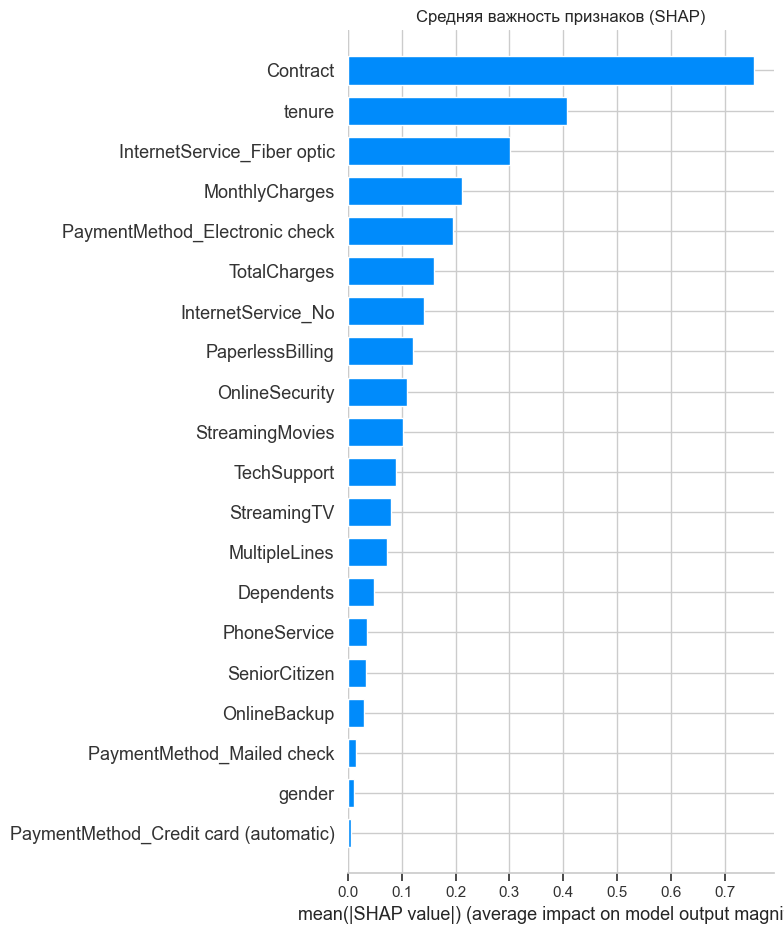

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values, X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=False,
)
plt.title("Средняя важность признаков (SHAP)")
plt.tight_layout()
plt.show()

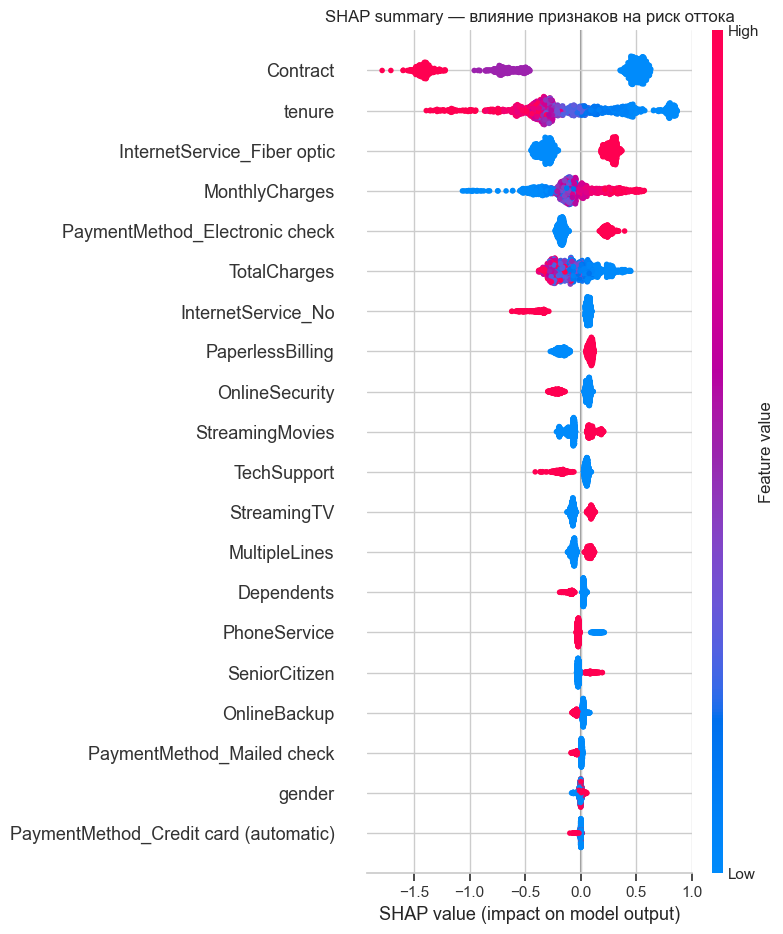

In [26]:
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values, X_test_transformed,
    feature_names=feature_names,
    show=False,
)
plt.title("SHAP summary — влияние признаков на риск оттока")
plt.tight_layout()
plt.show()

Клиент #1090
Предсказанная вероятность оттока: 0.9545
Реальный Churn: 1


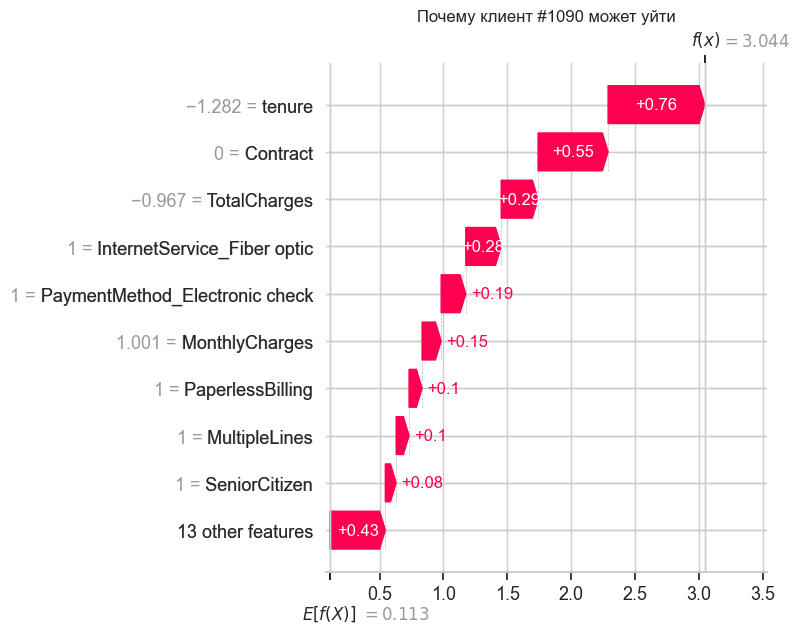

In [27]:
# Выберем клиента с высоким риском оттока (для наглядности)
y_pred_proba_all = final_model.predict_proba(X_test)[:, 1]
high_risk_idx = np.argmax(y_pred_proba_all)

print(f"Клиент #{high_risk_idx}")
print(f"Предсказанная вероятность оттока: {y_pred_proba_all[high_risk_idx]:.4f}")
print(f"Реальный Churn: {y_test.iloc[high_risk_idx]}")

# Waterfall plot
plt.figure(figsize=(10, 8))
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[high_risk_idx],
        base_values=explainer.expected_value,
        data=X_test_transformed[high_risk_idx],
        feature_names=feature_names,
    ),
    show=False,
)
plt.title(f"Почему клиент #{high_risk_idx} может уйти")
plt.tight_layout()
plt.show()

In [28]:
import joblib
import json

# Сохраняем финальную модель (она включает в себя и препроцессор!)
joblib.dump(final_model, "churn_model.joblib")

# Сохраняем словари кодирования, которые мы делали в Этапе 1
encodings = {
    "binary_map": {
        "gender": {"Female": 0, "Male": 1},
        "Partner": {"No": 0, "Yes": 1},
        "Dependents": {"No": 0, "Yes": 1},
        "PhoneService": {"No": 0, "Yes": 1},
        "PaperlessBilling": {"No": 0, "Yes": 1},
        "Churn": {"No": 0, "Yes": 1},
        "MultipleLines": {"No": 0, "Yes": 1},
        "OnlineSecurity": {"No": 0, "Yes": 1},
        "OnlineBackup": {"No": 0, "Yes": 1},
        "DeviceProtection": {"No": 0, "Yes": 1},
        "TechSupport": {"No": 0, "Yes": 1},
        "StreamingTV": {"No": 0, "Yes": 1},
        "StreamingMovies": {"No": 0, "Yes": 1},
    },
    "contract_map": {"Month-to-month": 0, "One year": 1, "Two year": 2},
    "internet_service_map": {"DSL": 0, "Fiber optic": 1, "No": 2},
    "payment_method_map": {
        "Electronic check": 0,
        "Mailed check": 1,
        "Bank transfer (automatic)": 2,
        "Credit card (automatic)": 3
    }
}

with open("encodings.json", "w") as f:
    json.dump(encodings, f, indent=2)

print("✅ Модель и энкодеры сохранены!")

✅ Модель и энкодеры сохранены!
